# 01 · Read the logs
- Five formats → **one table**: time, source, level, endpoint, status, latency, IP, exception, message
- Java stack traces (many lines) are joined to the error line that started them
- Plain pandas finds the incidents: the numbers the chatbot can trust

In [1]:
import os
os.environ['HF_HUB_OFFLINE'] = '1'          # models come from the local cache only
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
pd.set_option('display.max_colwidth', 120)
from logbot.parse import read_logs
df = read_logs()
print(len(df), 'records'); df.source.value_counts()

28829 records


source
apache_access    28647
app                143
apache_error        30
tomcat               6
deploy               3
Name: count, dtype: int64

In [2]:
df[df.level == 'ERROR'].sample(5, random_state=1)[['time', 'source', 'endpoint', 'status', 'exception', 'message']]

,time,source,endpoint,status,exception,message
2835,2026-10-13 10:33:24.698000+00:00,app,NaN,NaN,java.sql.SQLTransientConnectionException,"java.sql.SQLTransientConnectionException: HikariPool-1 - Connection is not available, request timed out after 30000ms."
12474,2026-10-14 11:02:13+00:00,apache_access,/api/login,502.0,NaN,POST /api/login 502 17426ms
12487,2026-10-14 11:02:50+00:00,apache_error,NaN,NaN,AH01102,(70007)The timeout specified has expired: AH01102: error reading status line from remote server 127.0.0.1:8080
12500,2026-10-14 11:03:35+00:00,apache_error,NaN,NaN,AH00957,(111)Connection refused: AH00957: http: attempt to connect to 127.0.0.1:8080 (localhost) failed
2822,2026-10-13 10:32:02.825000+00:00,app,NaN,NaN,java.sql.SQLTransientConnectionException,"java.sql.SQLTransientConnectionException: HikariPool-1 - Connection is not available, request timed out after 30000ms."


## The summary a person would want first

In [3]:
from logbot.tools import summary, timeline, top_exceptions
summary(df)

{'from': '2026-10-13 00:00:01+00:00',
 'to': '2026-10-15 23:59:37+00:00',
 'requests': 28647,
 'http_5xx': 84,
 'http_4xx': 866,
 'app_errors': 78,
 'app_warnings': 23,
 'top_exceptions': {'java.sql.SQLTransientConnectionException': 42,
  'java.lang.NullPointerException': 27,
  'AH00128': 12,
  'AH01102': 9,
  'AH00957': 9}}

## Problems over time (10-minute windows)

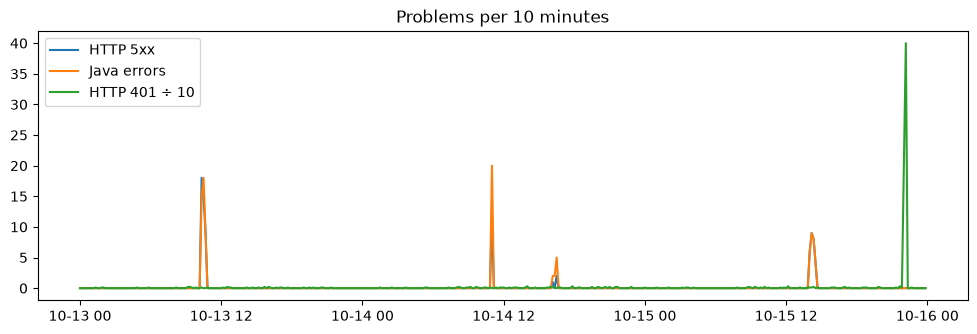

In [4]:
tl = timeline(df)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(tl.index, tl.http_5xx, label='HTTP 5xx'); ax.plot(tl.index, tl.app_errors, label='Java errors')
ax.plot(tl.index, tl.http_401 / 10, label='HTTP 401 ÷ 10'); ax.legend(); ax.set_title('Problems per 10 minutes'); plt.show()

## The spikes, as a table

In [5]:
spikes = tl[(tl.http_5xx >= 2) | (tl.http_401 >= 20) | (tl.p95_ms >= 2000)]
spikes

,requests,http_5xx,http_401,p95_ms,app_errors
time,,,,,
2026-10-13 10:20:00+00:00,88,18,1,30029.95,15
2026-10-13 10:30:00+00:00,88,15,0,30033.25,18
2026-10-13 10:40:00+00:00,95,9,0,30019.20,9
2026-10-14 11:00:00+00:00,88,12,0,39862.50,20
2026-10-14 16:30:00+00:00,82,2,0,6437.90,5
2026-10-15 14:00:00+00:00,100,6,1,133.35,6
2026-10-15 14:10:00+00:00,91,9,1,168.50,9
2026-10-15 14:20:00+00:00,92,8,2,168.40,8
2026-10-15 14:30:00+00:00,94,4,0,303.80,4


## Top exceptions

In [6]:
top_exceptions(df)

exception
java.sql.SQLTransientConnectionException    42
java.lang.NullPointerException              27
AH00128                                     12
AH01102                                      9
AH00957                                      9
java.net.SocketTimeoutException              9
java.lang.OutOfMemoryError                   1
Name: count, dtype: int64

## Link an Apache 502 to the Tomcat restart

In [7]:
t0, t1 = '2026-10-14 11:01', '2026-10-14 11:05'
w = df[(df.time >= t0) & (df.time <= t1) & (df.level != 'INFO') | (df.source == 'tomcat') & (df.time >= t0) & (df.time <= t1)]
w[['time', 'source', 'status', 'exception', 'message']].head(12)

,time,source,status,exception,message
12468,2026-10-14 11:02:10+00:00,apache_error,NaN,AH01102,(70007)The timeout specified has expired: AH01102: error reading status line from remote server 127.0.0.1:8080
12469,2026-10-14 11:02:10+00:00,tomcat,NaN,java.lang.OutOfMemoryError,"Exception in thread ""http-nio-8080-exec-17"" java.lang.OutOfMemoryError: Java heap space"
12470,2026-10-14 11:02:10+00:00,tomcat,NaN,NaN,Tomcat is shutting down after a fatal error
12471,2026-10-14 11:02:11+00:00,apache_access,503.0,NaN,GET /api/products 503 25575ms
12472,2026-10-14 11:02:11+00:00,apache_access,503.0,NaN,GET /api/orders/100 503 13493ms
12473,2026-10-14 11:02:13+00:00,apache_access,503.0,NaN,GET /api/products 503 42295ms
12474,2026-10-14 11:02:13+00:00,apache_access,502.0,NaN,POST /api/login 502 17426ms
12475,2026-10-14 11:02:15+00:00,apache_access,503.0,NaN,GET /api/products 503 42401ms
12476,2026-10-14 11:02:15+00:00,apache_error,NaN,AH00957,(111)Connection refused: AH00957: http: attempt to connect to 127.0.0.1:8080 (localhost) failed
12477,2026-10-14 11:02:20+00:00,apache_error,NaN,AH01102,(70007)The timeout specified has expired: AH01102: error reading status line from remote server 127.0.0.1:8080


In [8]:
import json
from logbot import DATA
key = json.loads((DATA / 'incidents.json').read_text())
hours = {pd.Timestamp(s).floor('h') for s in spikes.index}
found = [k['id'] for k in key if any(pd.Timestamp(k['start']).floor('h') <= h <= pd.Timestamp(k['end']) for h in hours)]
assert set(found) == {k['id'] for k in key}, found
print('✓ every planted incident shows up as a spike:', found)

✓ every planted incident shows up as a spike: ['db-pool', 'oom', 'gateway', 'bad-deploy', 'brute-force']
